# Simulationssoftware – Beispiel

Dieses Notebook zeigt alle Funktionen von `simulation.py` am CIGRE-Mittelspannungsnetz. Die vollständige Beschreibung steht in `README.md`.

In [1]:
import pandas as pd
import pandapower.networks as pn

import simulation as sim
from simulation import Profile, Diagram, Month

pd.set_option("display.max_columns", None)

## 1 Simulation anlegen

`sim.init(name, net)` kopiert das übergebene Netz. Mit `assignProfiles=True` werden die Profile sofort über die Namensregeln zugeordnet (CIGRE: `Load R…` → Haushalt, `Load CI…` → Gewerbe, `PV …` → PV, `WKA …` → Wind). Die Skalierung ergibt sich aus dem vorhandenen `p_mw`: bei Lasten als Jahreshöchstleistung, bei PV und Wind als Nennleistung.

In [2]:
sim1 = sim.init("cigre_basis", pn.create_cigre_network_mv(with_der="pv_wind"),
               assignProfiles=True, overwrite=True)
sim1

27 Profile zugeordnet: HAUSHALT: 10, GEWERBE: 8, PV: 8, WIND: 1


Simulation 'cigre_basis' (15 bus, 15 line, 2 trafo, 1 ext_grid, 8 switch, 18 load, 9 sgen)
  Herkunft: – | Änderungen: 0 | Ergebnisse: keine | letzter Lauf: –

In [3]:
sim1.elements().query("Tabelle in ['load', 'sgen']")

,Typ,Tabelle,Index,Bus,Profil,Skalierung
Name,,,,,,
Load R1,Last,load,0,Bus 1,HAUSHALT,66.157.911 kWh/a
Load R3,Last,load,1,Bus 3,HAUSHALT,1.219.778 kWh/a
Load R4,Last,load,2,Bus 4,HAUSHALT,1.904.566 kWh/a
Load R5,Last,load,3,Bus 5,HAUSHALT,3.209.943 kWh/a
Load R6,Last,load,4,Bus 6,HAUSHALT,2.418.157 kWh/a
Load R8,Last,load,5,Bus 8,HAUSHALT,2.589.354 kWh/a
Load R10,Last,load,6,Bus 10,HAUSHALT,2.097.163 kWh/a
Load R11,Last,load,7,Bus 11,HAUSHALT,1.455.174 kWh/a
Load R12,Last,load,8,Bus 12,HAUSHALT,66.157.911 kWh/a


## 2 Elemente abfragen

In [4]:
sim1.getElement("Load R11")

Tabelle                    net.load
Index                             7
name                       Load R11
bus                          Bus 11
p_mw                         0.3298
q_mvar                     0.082656
const_z_p_percent               0.0
const_i_p_percent               0.0
const_z_q_percent               0.0
const_i_q_percent               0.0
sn_mva                         0.34
scaling                         1.0
in_service                     True
type                            wye
profile                    HAUSHALT
annual_kwh           1455174.012062
cos_phi                        0.97
Name: Load R11, dtype: object

## 3 Netz ändern

Elemente hinzufügen, löschen und Parameter ändern. Busse werden über ihren Namen angegeben.

In [5]:
sim1.createElement(sim.Load("Neubaugebiet", bus="Bus 10", profile=Profile.HAUSHALT, annual_kwh=1_500_000))
sim1.createElement(sim.Generator("PV-Freifläche", bus="Bus 11", profile=Profile.PV, kwp=2000))
sim1.createElement(sim.Load("Kühlhaus", bus="Bus 9", profile=Profile.FEST, p_mw=0.3, cos_phi=0.9))
sim1.createElement(sim.Load("Hof Müller", bus="Bus 13", profile=Profile.LANDWIRTSCHAFT, annual_kwh=200_000))
sim1.createElement(sim.Load("Siedlung mit PV", bus="Bus 4", profile=Profile.HAUSHALT_PV, annual_kwh=500_000))
sim1.createElement(sim.Load("Siedlung mit PV+Speicher", bus="Bus 5", profile=Profile.HAUSHALT_PV_SPEICHER, annual_kwh=400_000))

sim1.changeParameter("Line 1-2", "length_km", 3.2)
sim1.changeParameter("Load CI9", "annual_kwh", 3_000_000)
sim1.changeParameter("WKA 7", "p_mw", 2.0)
sim1.deleteElement("PV 11")

In [6]:
sim1.changedParameters()

,Element,Typ,Parameter,alt,neu
0,Line 1-2,Leitung,length_km,2.820000e+00,3.200000e+00
1,Load CI9,Last,p_mw,5.737500e-01,8.163540e-01
2,Load CI9,Last,q_mvar,3.555783e-01,5.059308e-01
3,Load CI9,Last,annual_kwh,2.108460e+06,3.000000e+06
4,WKA 7,Erzeuger,p_mw,1.500000e+00,2.000000e+00


In [7]:
sim1.changedElements()

,Element,Typ,Änderung
0,Hof Müller,Last,hinzugefügt
1,Kühlhaus,Last,hinzugefügt
2,Neubaugebiet,Last,hinzugefügt
3,Siedlung mit PV,Last,hinzugefügt
4,Siedlung mit PV+Speicher,Last,hinzugefügt
5,PV-Freifläche,Erzeuger,hinzugefügt
6,PV 11,Erzeuger,gelöscht


In [8]:
sim1.history()

,zeit,aktion,element,tabelle,parameter,alt,neu
0,2026-10-25T15:30:51,Element hinzugefügt,Neubaugebiet,load,None,NaN,NaN
1,2026-10-25T15:30:51,Element hinzugefügt,PV-Freifläche,sgen,None,NaN,NaN
2,2026-10-25T15:30:52,Element hinzugefügt,Kühlhaus,load,None,NaN,NaN
3,2026-10-25T15:30:52,Element hinzugefügt,Hof Müller,load,None,NaN,NaN
4,2026-10-25T15:30:52,Element hinzugefügt,Siedlung mit PV,load,None,NaN,NaN
5,2026-10-25T15:30:52,Element hinzugefügt,Siedlung mit PV+Speicher,load,None,NaN,NaN
6,2026-10-25T15:30:52,Parameter geändert,Line 1-2,line,length_km,2.820000e+00,3.2
7,2026-10-25T15:30:52,Parameter geändert,Load CI9,load,annual_kwh,2.108460e+06,3000000.0
8,2026-10-25T15:30:52,Parameter geändert,WKA 7,sgen,p_mw,1.500000e+00,2.0
9,2026-10-25T15:30:52,Element gelöscht,PV 11,sgen,None,NaN,NaN


## 4 Simulation rechnen

Standard: 12 typische Wochen (je Monat eine), stündlich = 2016 Lastflüsse. Die Simulation wird danach automatisch gespeichert.

In [9]:
sim1.runSimulation()

Simulation 'cigre_basis': 2016 Lastflüsse in 110 s, nicht konvergiert: 0


Ergebnisse: 2016 Zeitschritte (2016 konvergiert), Monate: Januar, Februar, März, April, Mai, Juni, Juli, August, September, Oktober, November, Dezember
Tabellen: vm_pu, va_degree, line_loading, line_i_ka, trafo_loading, trafo_p_mw, ext_grid_p_mw, load_p_mw, sgen_p_mw, element_p_mw, info

In [10]:
sim1.summary()

Zeitschritte                                                         2016
konvergiert                                                          2016
U min [pu]                                                         0.9253
U max [pu]                                                           1.03
Stunden U < 0.9                                                         0
Stunden U > 1.1                                                         0
Leitung max [%]                                                      99.4
Stunden Leitung > 100 %                                                 0
Trafo max [%]                                                        87.0
Stunden Trafo > 100 %                                                   0
Stunden Rückspeisung ins vorgelagerte Netz                              0
max. Rückspeisung [MW]                                                0.0
Energie Lasten [MWh]                                              45135.9
Energie Erzeuger [MWh]                

In [11]:
sim1.summary(by="month")

,Zeitschritte,konvergiert,U min [pu],U max [pu],Stunden U < 0.9,Stunden U > 1.1,Leitung max [%],Stunden Leitung > 100 %,Trafo max [%],Stunden Trafo > 100 %,Stunden Rückspeisung ins vorgelagerte Netz,max. Rückspeisung [MW],Energie Lasten [MWh],Energie Erzeuger [MWh]
Monat,,,,,,,,,,,,,,
Januar,168,168,0.9264,1.03,0,0,99.4,0,87.0,0,0,0.0,4391.7,167.6
Februar,168,168,0.9253,1.03,0,0,99.0,0,86.1,0,0,0.0,4310.1,130.5
März,168,168,0.9364,1.03,0,0,90.4,0,77.9,0,0,0.0,4003.9,142.5
April,168,168,0.9533,1.03,0,0,74.6,0,66.2,0,0,0.0,3769.1,141.6
Mai,168,168,0.9659,1.03,0,0,61.0,0,57.6,0,0,0.0,3364.6,155.5
Juni,168,168,0.9685,1.03,0,0,60.3,0,57.5,0,0,0.0,3329.4,175.8
Juli,168,168,0.9693,1.03,0,0,59.2,0,56.6,0,0,0.0,3281.3,110.4
August,168,168,0.9688,1.03,0,0,60.5,0,53.8,0,0,0.0,3238.0,134.4
September,168,168,0.9597,1.03,0,0,68.7,0,60.9,0,0,0.0,3328.6,166.4


In [12]:
sim1.getElement("Bus 11")

Tabelle                           net.bus
Index                                  11
name                               Bus 11
vn_kv                                20.0
type                                    b
zone                             CIGRE_MV
in_service                           True
Ergebnis Spannung min [pu]         0.9253
Ergebnis Spannung max [pu]         1.0195
Ergebnis Spannung Mittel [pu]      0.9806
Name: Bus 11, dtype: object

## 5 Diagramme

`createDiagram(diagram, elements, months=..., layout=...)`

- `months`: ein Monat oder eine Liste, z. B. `Month.JULY` oder `[Month.JANUARY, Month.JULY]`
- `layout`: `"week"` (je Monat ein Diagramm), `"season"`, `"overview"`, `"boxplot"`

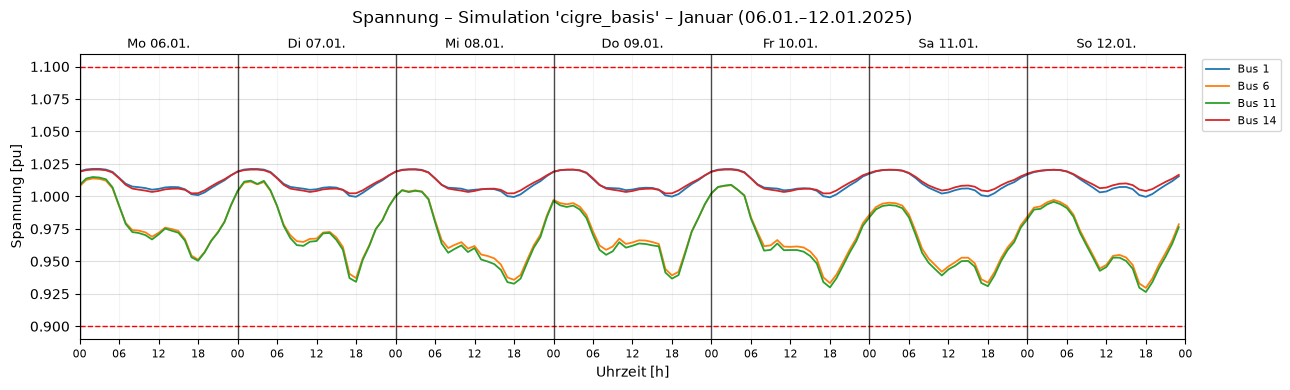

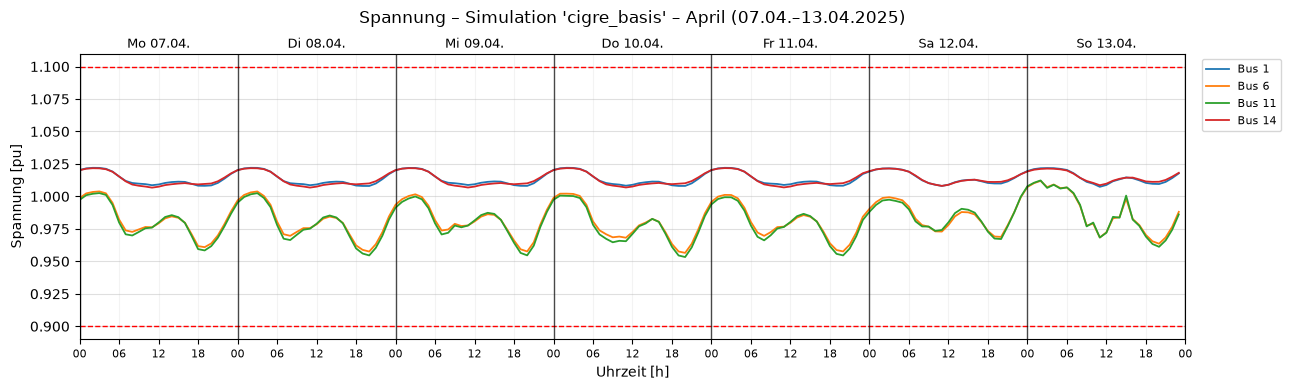

In [13]:
sim1.createDiagram(Diagram.VOLTAGE, ["Bus 1", "Bus 6", "Bus 11", "Bus 14"], months=[Month.JANUARY, Month.APRIL])

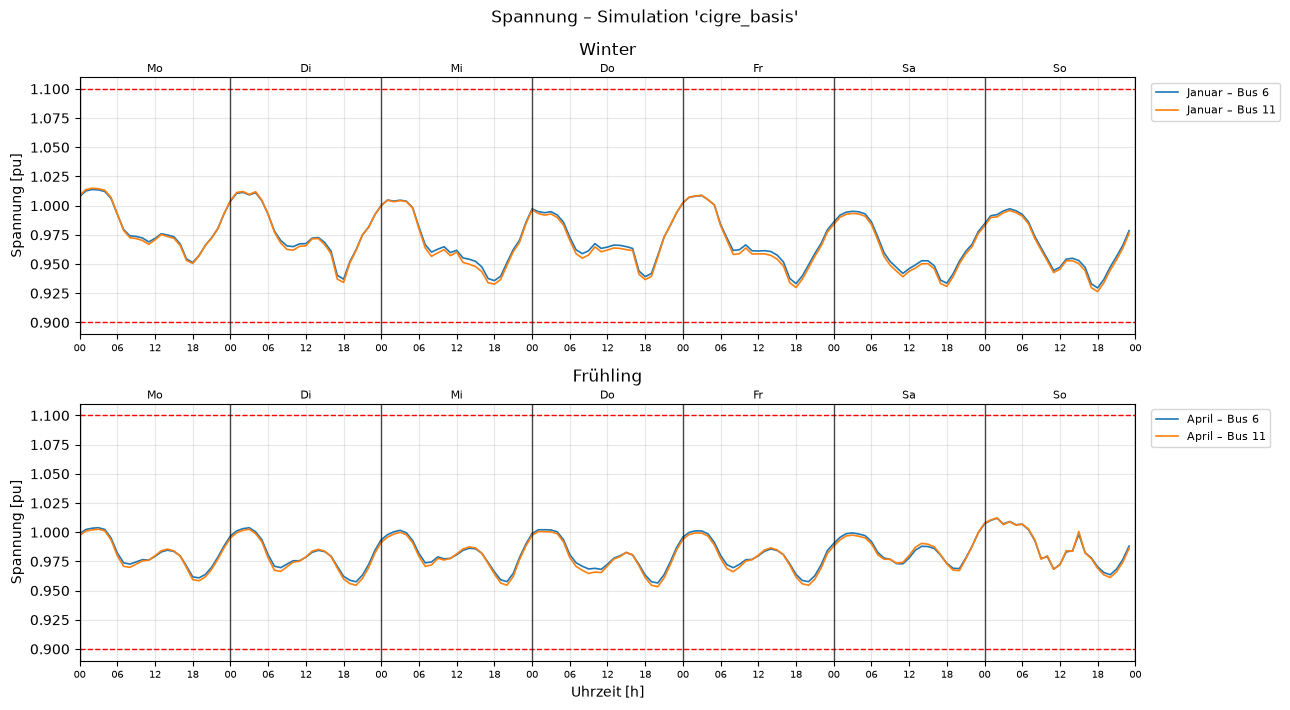

In [14]:
sim1.createDiagram(Diagram.VOLTAGE, ["Bus 6", "Bus 11"], months=[Month.JANUARY, Month.APRIL], layout="season")

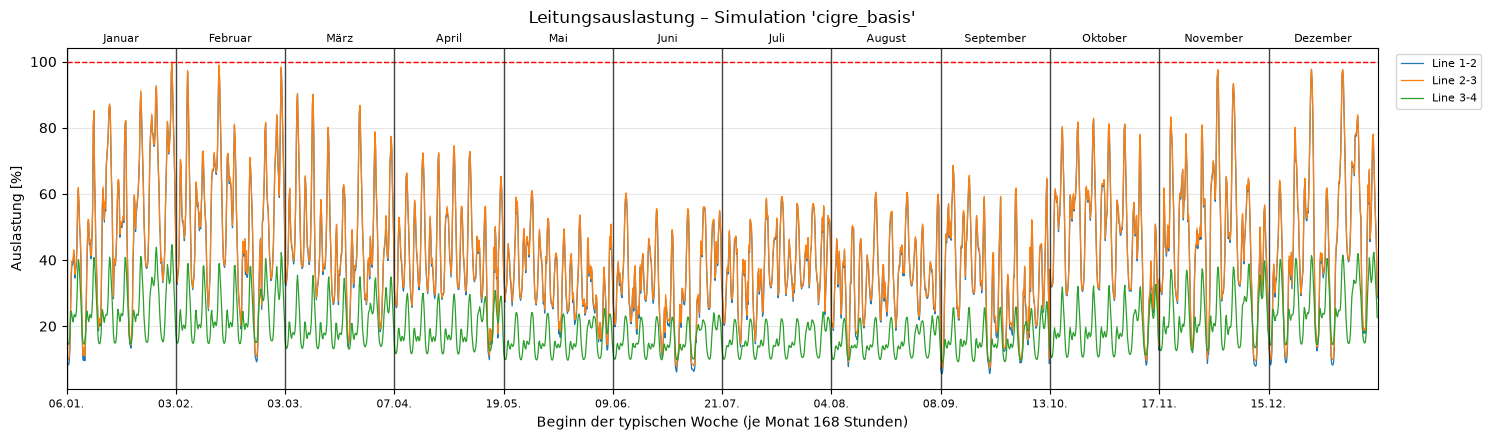

In [15]:
sim1.createDiagram(Diagram.LINE_LOADING, ["Line 1-2", "Line 2-3", "Line 3-4"], layout="overview")

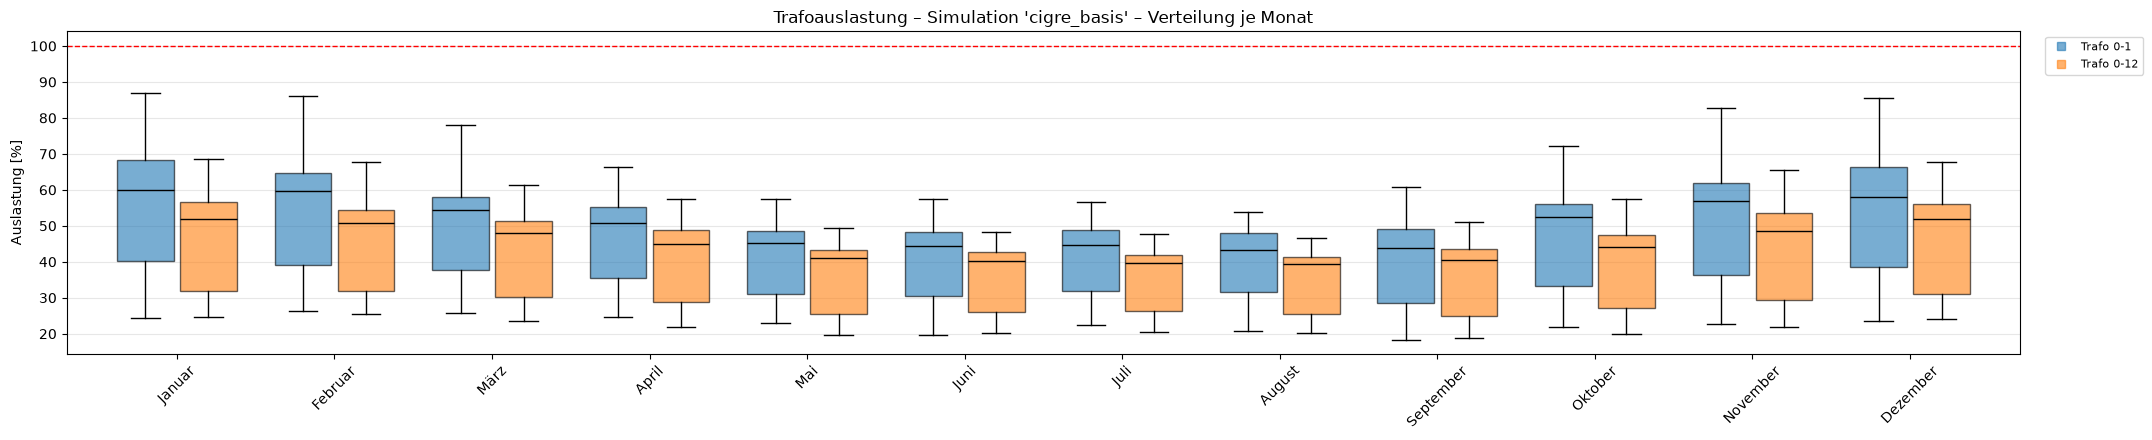

In [16]:
sim1.createDiagram(Diagram.TRAFO_LOADING, ["Trafo 0-1", "Trafo 0-12"], layout="boxplot")

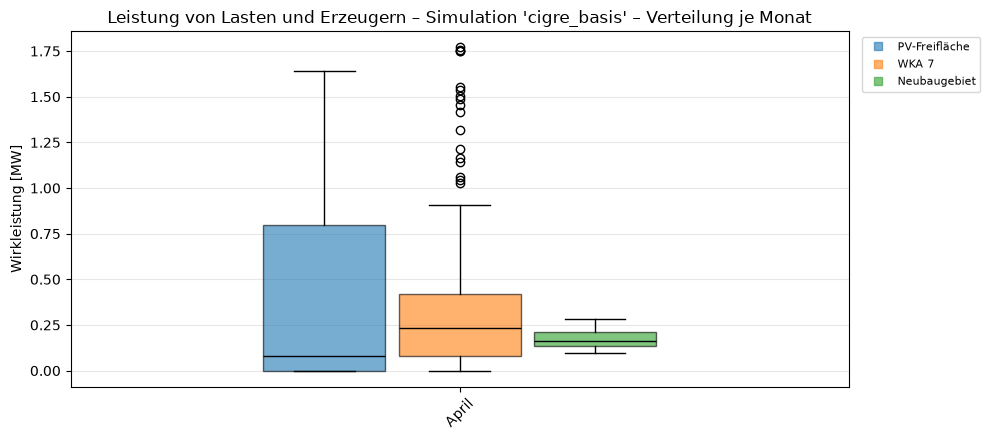

In [17]:
sim1.createDiagram(Diagram.ELEMENT_POWER, ["PV-Freifläche", "WKA 7", "Neubaugebiet"], months=Month.APRIL, layout="boxplot")

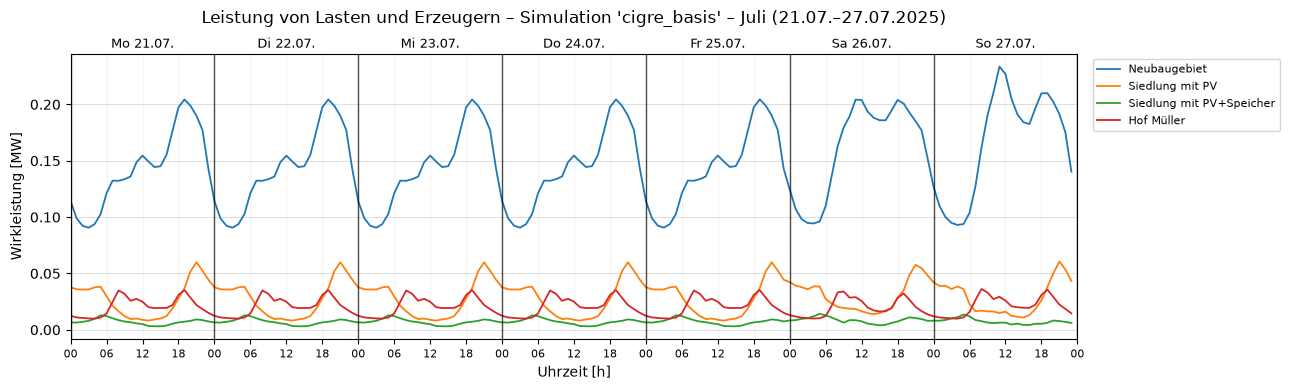

In [18]:
sim1.createDiagram(Diagram.ELEMENT_POWER, ["Neubaugebiet", "Siedlung mit PV", "Siedlung mit PV+Speicher", "Hof Müller"],
                   months=Month.JULY)

### Markierungen

`markers` ist eine Liste von `(farbe, wert, text)`. Eine Zahl ergibt eine waagerechte Linie, ein Zeitpunkt eine senkrechte. Optional legt ein 4. Element den Linienstil fest.

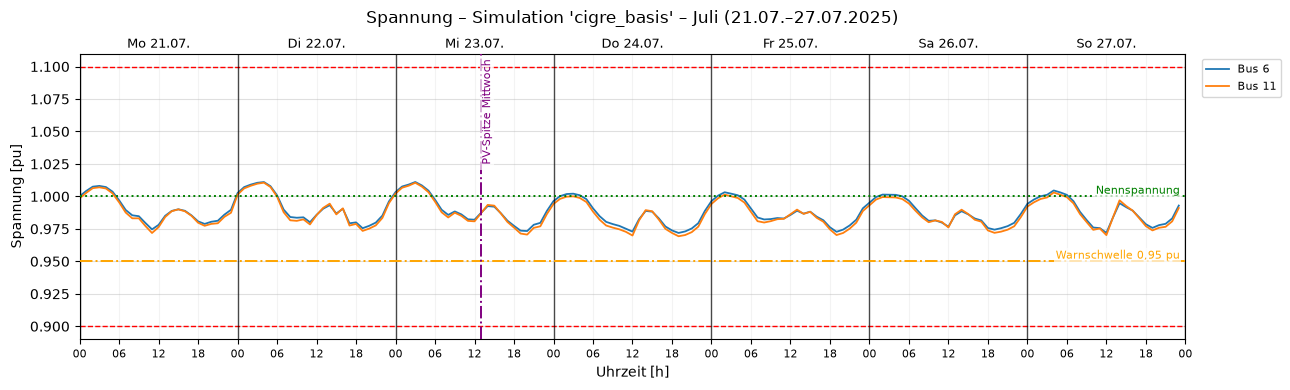

In [19]:
sim1.createDiagram(Diagram.VOLTAGE, ["Bus 6", "Bus 11"], months=Month.JULY, markers=[
    ("orange", 0.95, "Warnschwelle 0,95 pu"),
    ("green", 1.00, "Nennspannung", ":"),
    ("purple", "2025-07-23 13:00", "PV-Spitze Mittwoch"),
])

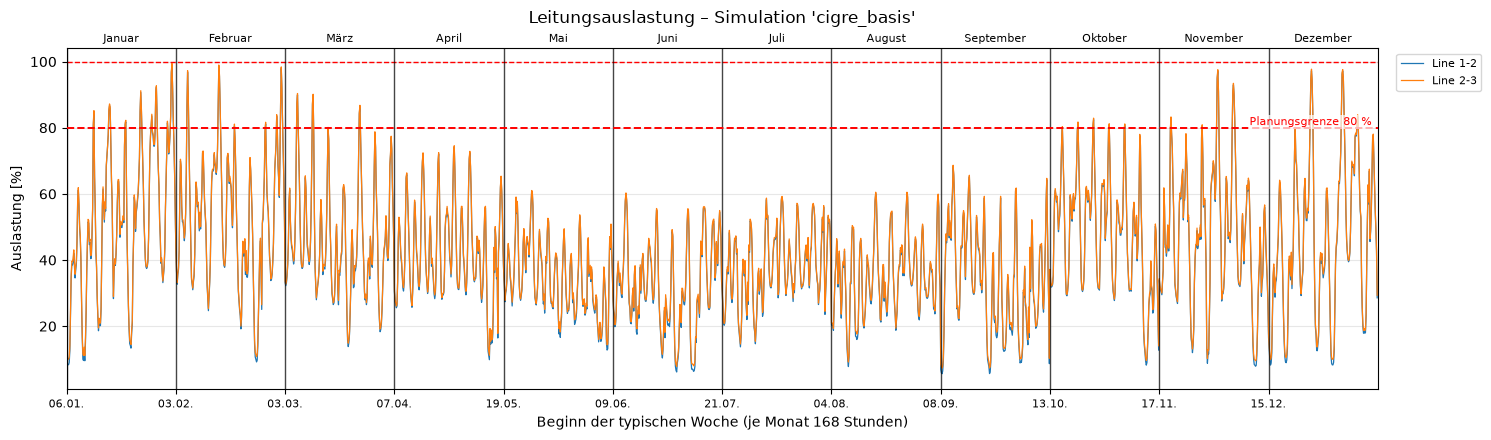

In [20]:
sim1.createDiagram(Diagram.LINE_LOADING, ["Line 1-2", "Line 2-3"], layout="overview",
                   markers=[("red", 80, "Planungsgrenze 80 %", "--")])

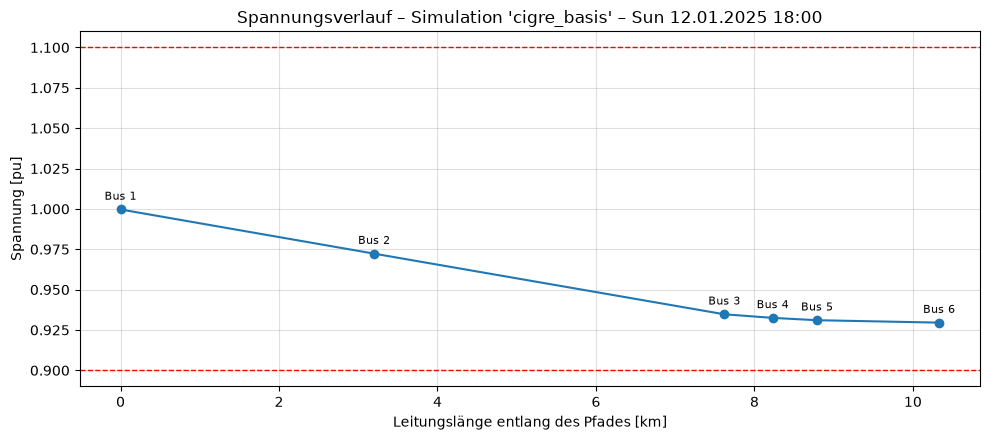

In [21]:
# Spannung entlang eines Pfades zum Zeitpunkt der niedrigsten Spannung
sim1.createDiagram(Diagram.VOLTAGE_PROFILE, ["Bus 1", "Bus 2", "Bus 3", "Bus 4", "Bus 5", "Bus 6"], time="min")

## 6 Kopieren und vergleichen

Die Baseline der Kopie ist der aktuelle Stand von `sim1`. Änderungen an `sim2` werden also gegenüber `sim1` angezeigt.

In [22]:
sim2 = sim1.copy("cigre_mehr_pv", overwrite=True)
sim2.createElement(sim.Generator("PV-Park", bus="Bus 6", profile=Profile.PV, kwp=4000))
sim2.changeParameter("PV-Freifläche", "kwp", 4000)
display(sim2.changedElements())
display(sim2.changedParameters())
sim2.runSimulation()

,Element,Typ,Änderung
0,PV-Park,Erzeuger,hinzugefügt


,Element,Typ,Parameter,alt,neu
0,PV-Freifläche,Erzeuger,p_mw,2.0,4.0
1,PV-Freifläche,Erzeuger,kwp,2000.0,4000.0


Simulation 'cigre_mehr_pv': 2016 Lastflüsse in 105 s, nicht konvergiert: 0


Ergebnisse: 2016 Zeitschritte (2016 konvergiert), Monate: Januar, Februar, März, April, Mai, Juni, Juli, August, September, Oktober, November, Dezember
Tabellen: vm_pu, va_degree, line_loading, line_i_ka, trafo_loading, trafo_p_mw, ext_grid_p_mw, load_p_mw, sgen_p_mw, element_p_mw, info

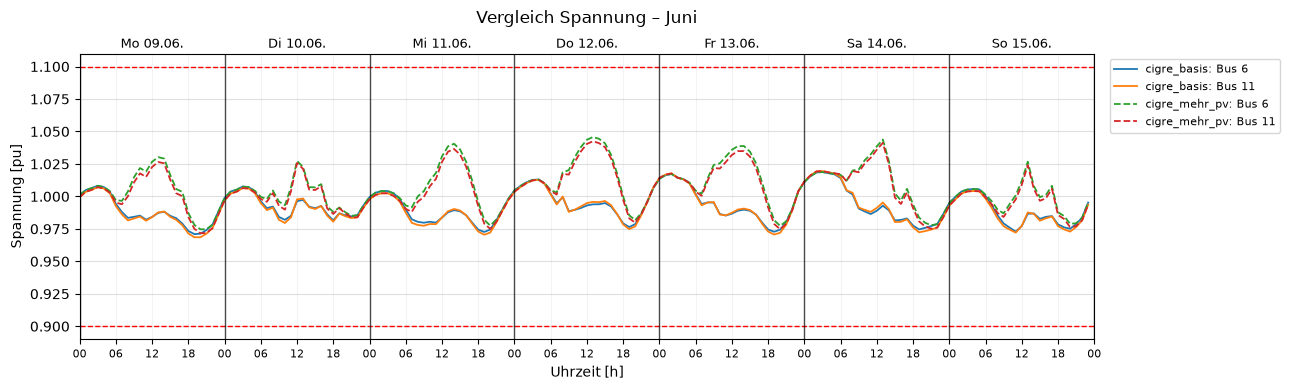

In [23]:
sim.compare([sim1, sim2], Diagram.VOLTAGE, ["Bus 6", "Bus 11"], months=Month.JUNE)

## 7 Gespeicherte Simulationen

In [24]:
sim.listSimulations()

,Herkunft,erstellt,geändert,letzter Lauf,Ergebnisse,Änderungen
Name,,,,,,
cigre_basis,–,2026-10-25T15:30:50,2026-10-25T15:30:52,2026-10-25T15:32:44,aktuell,10
cigre_mehr_pv,cigre_basis,2026-10-25T15:33:00,2026-10-25T15:33:00,2026-10-25T15:34:46,aktuell,2


In [25]:
sim3 = sim.loadSimulation("cigre_basis")
sim3

Simulation 'cigre_basis' (15 bus, 15 line, 2 trafo, 1 ext_grid, 8 switch, 23 load, 9 sgen)
  Herkunft: – | Änderungen: 10 | Ergebnisse: aktuell | letzter Lauf: 2026-10-25T15:32:44

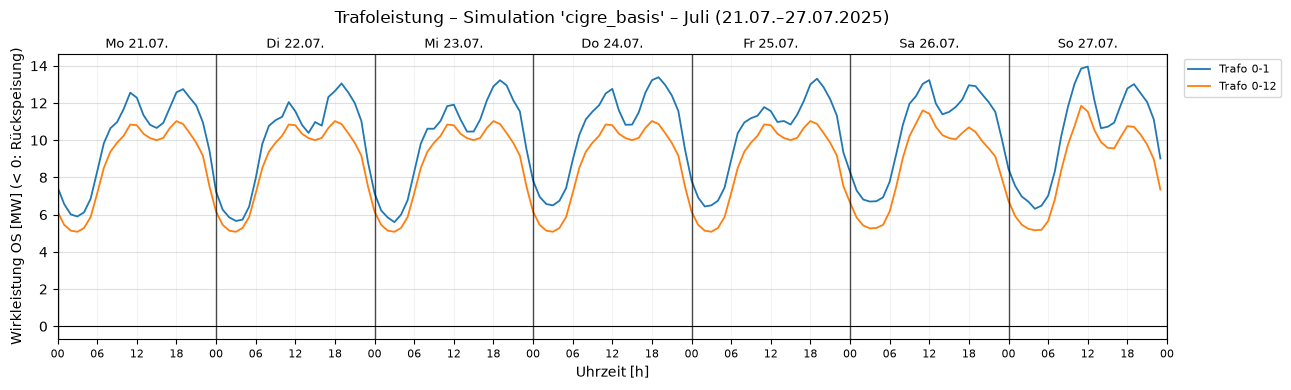

In [26]:
sim3.createDiagram(Diagram.TRAFO_POWER, ["Trafo 0-1", "Trafo 0-12"], months=Month.JULY)